In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

## **Postprocess Data**

In [ ]:
technologies_df = visualisation.load_df("../data/visualisation_files/df_technologies_cost.parquet")
def dicts_to_tuples(units):
    return [(u.get('text', ''), u.get('exponent', None), u.get('unit_uri', ''), u.get('year', None)) 
            for u in units]

technologies_df['unit_normalized'] = technologies_df['unit_normalized'].apply(dicts_to_tuples)

In [ ]:
technologies_df["property"].value_counts()

In [ ]:
print(technologies_df["unit_normalized"].value_counts())
print("--------------------------------------------------------------------------------")
exclude_values = [
    [(None, None, 'http://qudt.org/vocab/unit/UNITLESS', None)],
    [('%', 1.0, 'http://qudt.org/vocab/unit/PERCENT', None)],
    [(None, None, 'http://qudt.org/vocab/unit/UNITLESS', None)]   
]
technologies_df = technologies_df[~technologies_df["unit_normalized"].isin(exclude_values)]
print(technologies_df["unit_normalized"].value_counts())

In [ ]:
#target_unit = [("GW", 1.0, "http://qudt.org/vocab/unit/MegaW", None)]
target_unit = [("$", 1.0, "http://qudt.org/vocab/currency/USD", None), ("kg", -1.0, "http://qudt.org/vocab/unit/KiloGM", None)]
technologies_df['value_converted'] = technologies_df.apply(visualisation.convert_row, axis=1, args=(target_unit,))

In [ ]:
technologies_df = technologies_df[technologies_df["value_converted"].notna()]
technologies_df = technologies_df.reset_index(drop=True)
technologies_df.to_excel("../data/visualisation_files/unit_converted/df_technologies_capacity_usd_kg.xlsx")

## **Visualise Results**

In [ ]:
farbe_hydrogen = {
    'Hydrogen': '#000000',            # black
    'Blue': '#0072B2',       # blue
    'Grey': '#999999',       # gray
    'Yellow': '#E69F00',     # orange (statt gelb)
    'Green': '#009E73',      # green
}

#### **Levelized Cost**

In [ ]:
cost_kg = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_cost_usd_kg.xlsx")
cost_kwh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_cost_usd_kwh.xlsx")

#### Select Entities

In [ ]:
# ---------------------------------------- ENTITY BASE MAPPING -----------------------------------

# cost_kg = cost_kg[cost_kg["entity_base_mapping"].isin(['hydrogen'])]
cost_kwh = cost_kwh[cost_kwh["entity_base_mapping"].isin(['pv', 'wind turbine', 'natural gas'])]


# ---------------------------------------- ENTITY MAPPING -----------------------------------

# cost_kwh = cost_kwh[cost_kwh["entity_mapping"].isin(['Battery', 'Lithium-Ion Battery'])]
# cost_kwh["entity_mapping"] = cost_kwh["entity_mapping"].replace({
#     'Lithium-Ion Battery': 'Lithium Ion',
#     'Lead Acid Battery': 'Lead Acid',
#     'Nickel-Iron Battery': 'Nickel-Iron',
#     'Lithium Iron Phosphate Battery': 'Lithium Iron Phosphate',
# })

# cost_kwh = cost_kwh[cost_kwh["entity_mapping"].isin(['Wind Turbine', 'Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# cost_kwh["entity_mapping"] = cost_kwh["entity_mapping"].replace({
#     'Wind Turbine': 'Wind Turbine',
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore',
# })

# cost_kwh = cost_kwh[cost_kwh["entity_mapping"].isin(['PVSystem', 'Hybrid PV System', 'Utility-scale PV System'])]
# cost_kwh["entity_mapping"] = cost_kwh["entity_mapping"].replace({
#     'PVSystem': 'PV',
#     'Hybrid PV System': 'Hybrid',
#     'Utility-scale PV System': 'Utility-scale',
#     'Rooftop PV System': 'Rooftop',
#     'Photovoltaic-Thermal System (PVT)': 'PVT'
# })

cost_kg = cost_kg[cost_kg["entity_mapping"].isin(['Hydrogen', 'Green Hydrogen'])]
cost_kg["entity_mapping"] = cost_kg["entity_mapping"].replace({
    'Hydrogen': 'Hydrogen',
    'Blue Hydrogen': 'Blue',
    'Grey Hydrogen': 'Grey',
    'Yellow Hydrogen': 'Yellow',
    'Green Hydrogen': 'Green'
})

In [ ]:
# cost_kwh = convert_spatial(cost_kwh)
# print(cost_kwh["entity_mapping"].value_counts())
# print(len(cost_kwh))

cost_kg = visualisation.convert_spatial(cost_kg)
print(cost_kg["entity_mapping"].value_counts())
print(len(cost_kg))

In [ ]:
datasets = [
    {
    'df': cost_kg,
    'marker': 'o',
    'value_column': 'value_converted',
    'color_column': 'entity_mapping', 
    'size_legend_title': 'LCOH [$/kg]', 
    'size_legend_position': (0.261,0.07),
    },
    # {
    # 'df': cost_kwh,
    # 'marker': 'o',
    # 'value_column': 'value_converted',
    # 'color_column': 'entity_mapping', 
    # 'size_legend_title': 'LCOE [$/kWh]', 
    # 'size_legend_position': (0.291,0.07),
    # },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    'entity_mapping',
    title="Geographical Distribution of Technology Mentions in Scientific Literature",
    color_legend_position=(0.117,0.07),
    color_legend_title="Hydrogen Type",
    figsize=(14, 8),
    jitter_strength=0,
    default_point_size=15,
    palette=farbe_hydrogen
)
fig.savefig("../data/figures/results/level_cost/hydrogen_cost_worldmap.pdf", bbox_inches='tight')

#### **Lifetime**

In [3]:
lifetime = pd.read_parquet("../data/visualisation_files/df_technologies_lifetime.parquet")
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]    1311
[{'exponent': 1.0, 'text': 'year', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]       76
[{'exponent': 1.0, 'text': 'yr', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]          8
[{'exponent': 1.0, 'text': 'yrs', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]         4
[{'exponent': 1.0, 'text': 'a', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]           2
[{'exponent': 1.0, 'text': 'Years', 'unit_uri': 'http://qudt.org/vocab/unit/YR', 'year': None}]       2
Name: count, dtype: int64

#### Select Entities

In [4]:
lifetime = visualisation.convert_spatial(lifetime)
print(lifetime["entity_base_mapping"].value_counts())
len(lifetime)

entity_base_mapping
pv              119
battery          37
wind turbine     35
electrolyzer      7
natural gas       1
hydrogen          1
Name: count, dtype: int64


c:\Gorres\Projekte\quinex_application\quinex_application\quinex_visualisation.py:819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['spatial_scope'] = df['spatial_scope'].apply(
c:\Gorres\Projekte\quinex_application\quinex_application\quinex_visualisation.py:825: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['latitude'] = df['spatial_scope'].apply(
c:\Gorres\Projekte\quinex_application\quinex_application\quinex_visualisation.py:829: SettingWithCopyWarning: 
A value is trying to be set on a copy of a s

200

In [5]:
lifetime_bat = lifetime[lifetime["entity_base_mapping"].isin(['battery'])]

In [6]:
lifetime_pv = lifetime[lifetime["entity_base_mapping"].isin(['pv'])]

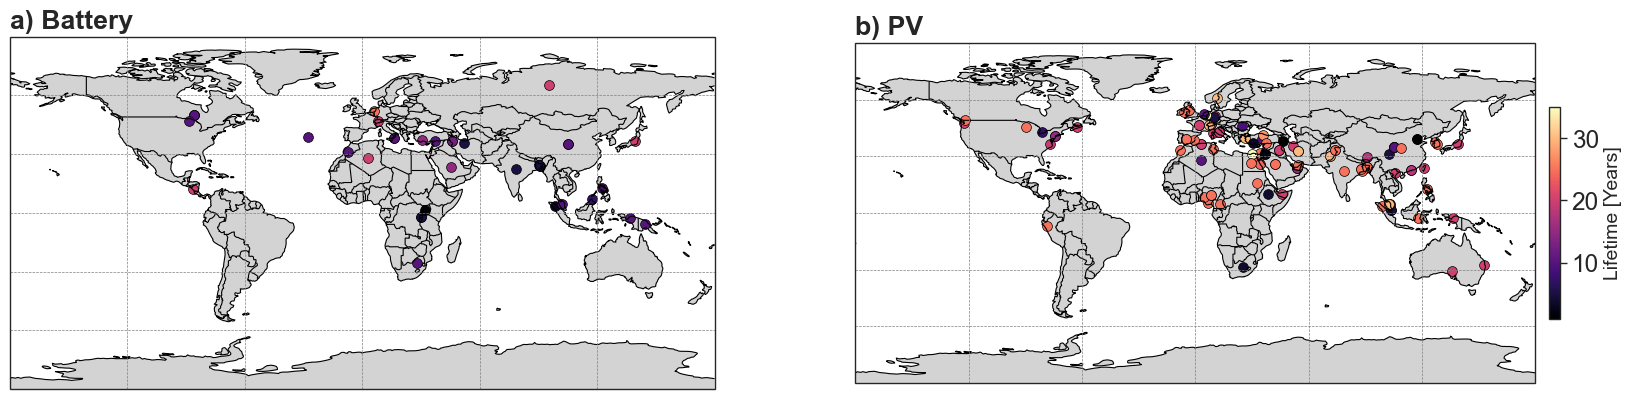

In [9]:
datasets = [
    {
    'df': lifetime_bat,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_base_mapping', 
    'title': 'a) Battery'
    },
    {
    'df': lifetime_pv,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_base_mapping', 
    'title': 'b) PV'
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="Lifetime [Years]",
    figsize=(20, 10),
    jitter_strength=0,
    default_point_size=50,
    cmap="magma"
)
fig.savefig("../data/figures/results/lifetime/windturbine_lifetime_worldmap.pdf", bbox_inches='tight')

#### **Efficiency**

In [ ]:
efficiency = pd.read_parquet("../data/visualisation_files/df_technologies_efficiency.parquet")
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

#### Select Entities

In [ ]:
efficiency = efficiency[efficiency["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

In [ ]:
efficiency = visualisation.convert_spatial(efficiency)
print(efficiency["entity_base_mapping"].value_counts())
len(efficiency)

In [ ]:
datasets = [
    {
    'df': efficiency,
    'marker': 'o',
    'value_column': 'value_normalized',
    'color_column': 'entity_base_mapping', 
    'size_legend_title': 'Efficiency [%]', 
    'size_legend_position': (0.117,0.07),
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    'entity_base_mapping',
    title="Geographical Distribution of Technology Mentions in Scientific Literature",
    color_legend_position=(0.247,0.026),
    color_legend_title="Technology Type",
    figsize=(14, 8),
    jitter_strength=0,
    default_point_size=10
)
fig.savefig("../data/figures/results/efficiency/technologies_efficiency_worldmap.pdf", bbox_inches='tight')

#### **Capacity**

In [ ]:
capacity = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capacity_mw.xlsx")

#### Select Entities

In [ ]:
#capacity = capacity[capacity["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

#capacity = capacity[capacity["entity_mapping"].isin(['PVSystem', 'Wind Turbine'])]

# capacity = capacity[capacity["entity_mapping"].isin(['Offshore Wind Turbine', 'Floating Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# capacity["entity_mapping"] = capacity["entity_mapping"].replace({
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore'
# })

capacity = capacity[capacity["entity_mapping"].isin(['Hybrid PV System', 'Utility-scale PV System', 'Rooftop PV System', 'Photovoltaic-Thermal System (PVT)'])]
capacity["entity_mapping"] = capacity["entity_mapping"].replace({
    'Hybrid PV System': 'Hybrid PV',
    'Utility-scale PV System': 'Utility-scale PV',
    'Rooftop PV System': 'Rooftop PV',
    'Photovoltaic-Thermal System (PVT)': 'PVT'
})

capacity = capacity[capacity["property"].isin(['installed capacity'])]

In [ ]:
capacity = visualisation.convert_spatial(capacity)
print(capacity["entity_mapping"].value_counts().iloc[:20])

In [ ]:
datasets = [
    {
    'df': capacity,
    'marker': 'o',
    'value_column': 'value_converted',
    'color_column': 'entity_mapping', 
    'size_legend_title': 'Installed Capacity [MW]', 
    'size_legend_position': (0.315,0.07),
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    'entity_mapping',
    title="Geographical Distribution of Technology Mentions in Scientific Literature",
    color_legend_position=(0.117,0.07),
    color_legend_title="PV Type",
    figsize=(14, 8),
    jitter_strength=0,
    default_point_size=15
)
fig.savefig("../data/figures/results/capacity/pv_capacity_worldmap.pdf", bbox_inches='tight')

#### Emission 

In [ ]:
emission = pd.read_parquet("../data/visualisation_files/df_emission.parquet")
emission["unit_normalized"].value_counts()
emission = emission[emission['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
emission["unit_normalized"].value_counts()

#### Select Entities

In [ ]:
emission = emission[emission["property_mapping"] == "GHG emission"]

In [ ]:
emission = visualisation.convert_spatial(emission)
print(emission["property_mapping"].value_counts())

In [ ]:
emission = emission[(emission["value_normalized"] >= 0) & (emission["value_normalized"] <= 100)]

In [ ]:
datasets = [
    {
    'df': emission,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_mapping', 
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="GHG Emission (%)",
    figsize=(14, 7),
    jitter_strength=0,
    default_point_size=40,
    cmap="magma"
)
fig.savefig("../data/figures/results/capacity/ghg_emission_worldmap.pdf", bbox_inches='tight')